# 03 · anemoi-models: the model itself

**AIWCAS 2026 · Anemoi hands-on · about 15 minutes**

Notebook 01 gave us a dataset as a `(dates, variables, ensembles, gridpoints)` array with statistics.
Notebook 02 built an encoder–processor–decoder graph (`HeteroData`).
This notebook joins the two into a **neural network**, using `anemoi-models` (v0.19).

You will:

1. build a *tiny* model on CPU from the **same Hydra config groups that anemoi-training uses**,
2. push a real batch through it and watch the tensor shapes change,
3. see the pre- and post-processing that ships *inside* the model (normaliser, imputer, bounding),
4. swap the processor (GraphTransformer, GNN, sliding-window Transformer) and compare size and speed.

Training (configs, the Lightning loop, losses) comes in notebook 04.

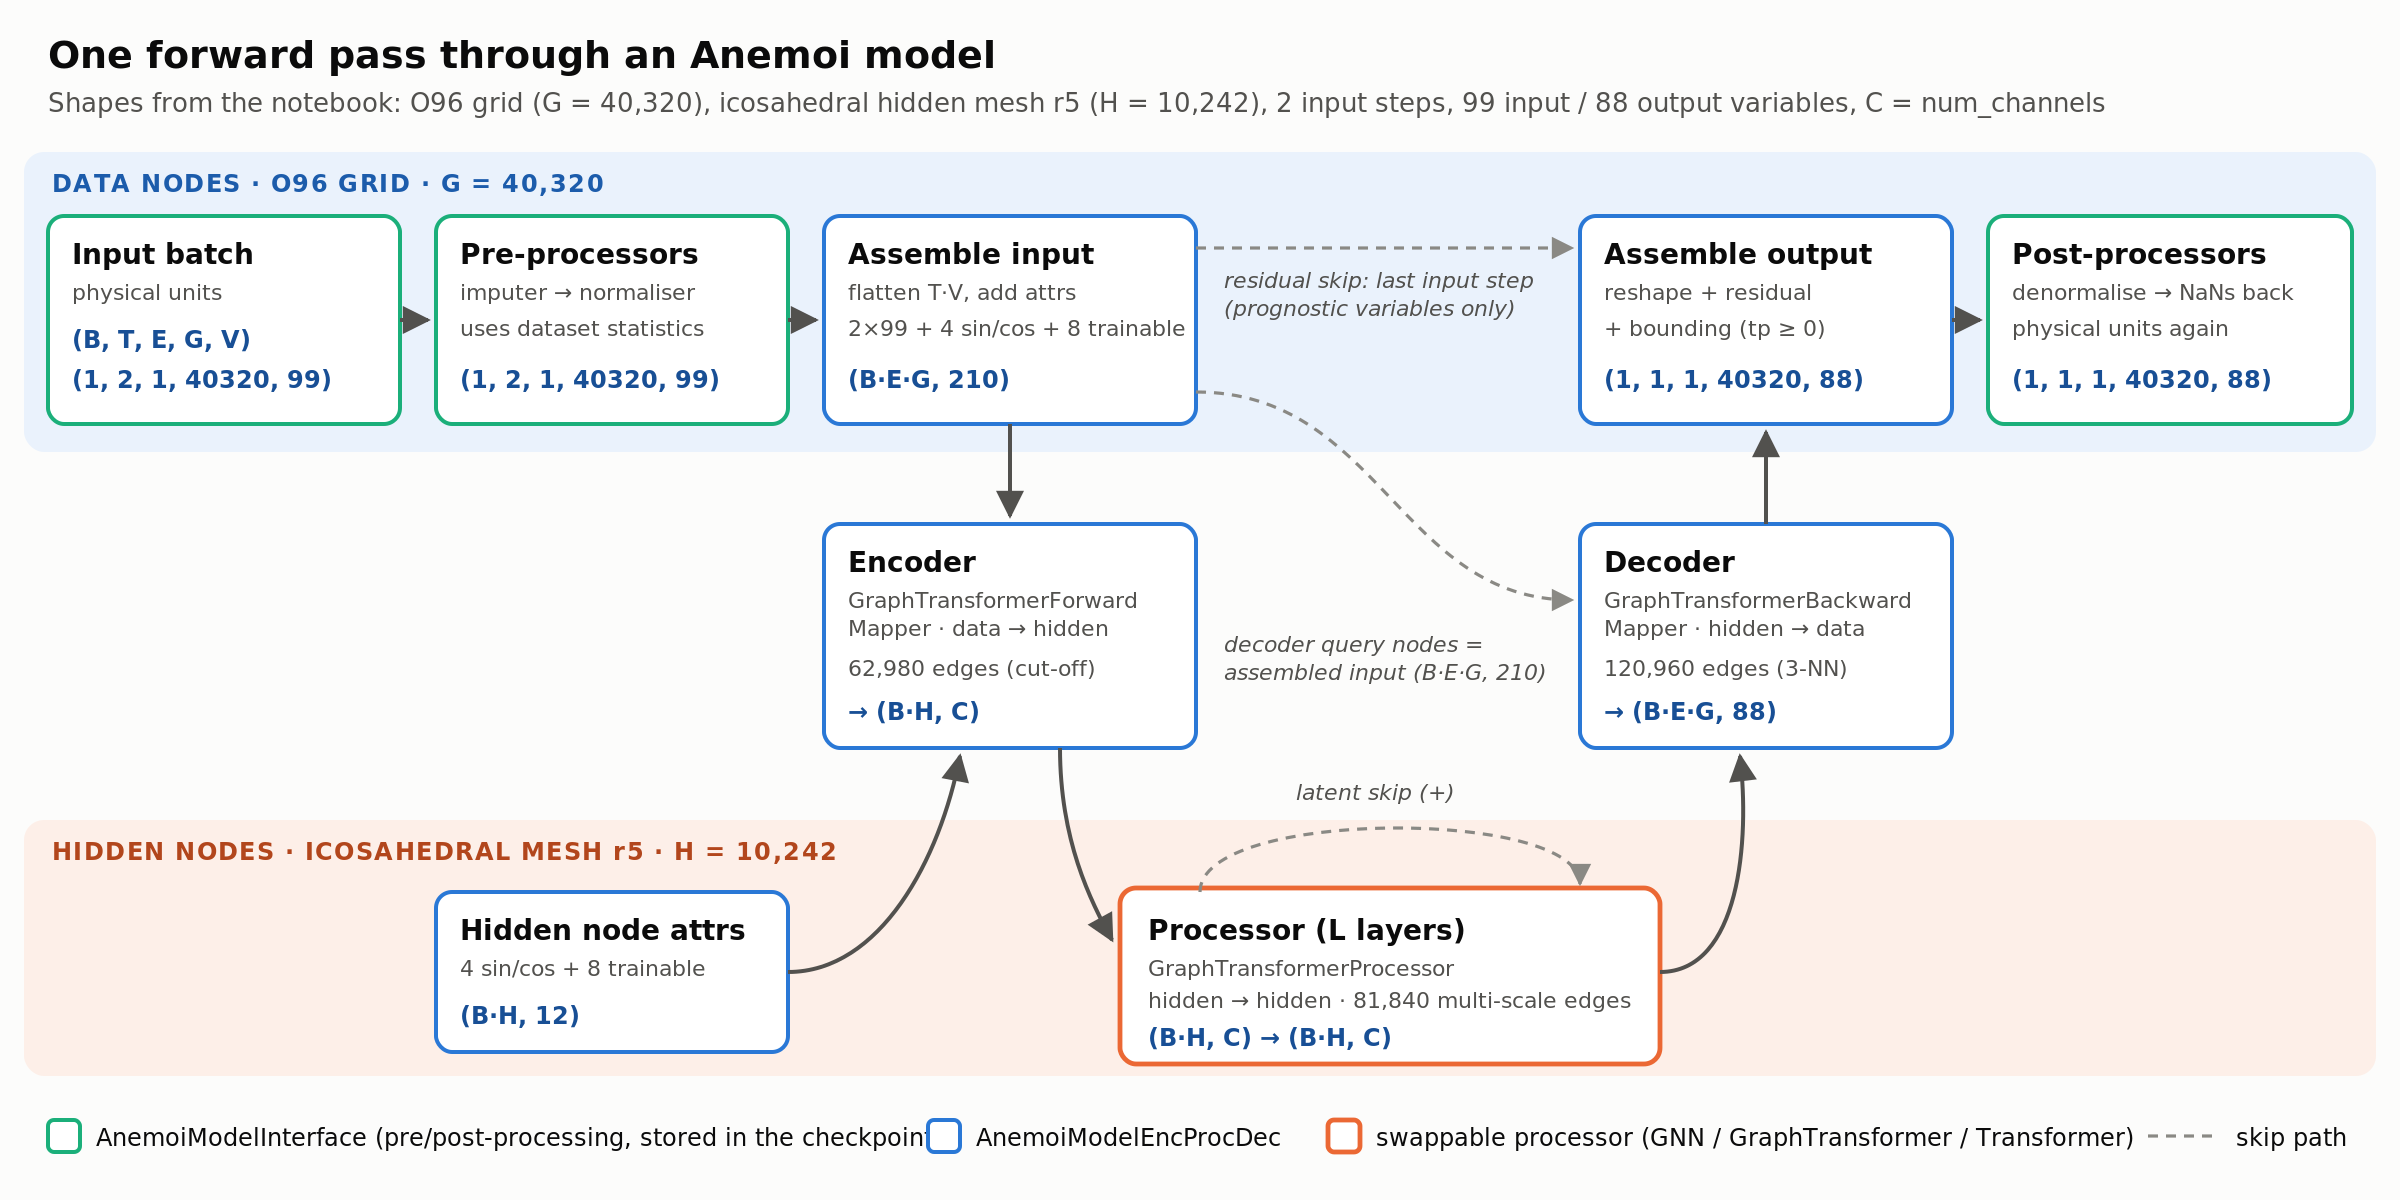

| Section | Minutes |
|---|---|
| 0 Setup | 1 |
| 1 Architecture in code | 2 |
| 2 From config to model | 3 |
| 3 A forward pass, stage by stage | 3 |
| 4 Pre-/post-processing in the model | 3 |
| 5 Swap the processor | 2 |
| 6 Try it (2 exercises) | extra |

## 0 · Setup (1 min)

All paths are in the next cell. Change them there if your data or graph live elsewhere.
Everything runs on CPU in about a minute; the imports alone take ~45 s on a Leonardo login node (the venv is on Lustre).

In [1]:
import os
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Inputs (read-only): the dataset from notebook 01 and the graph from notebook 02
DATASET = Path(os.environ["WORK"]) / "a08trd25/data/anemoi/aifs-ea-an-oper-0001-mars-o96-2017-2017-6h-v8-testing.zarr"
GRAPH = Path(os.environ["SCRATCH"]) / "aiwcas26/graphs/o96_tri5.pt"
# anemoi-training's Hydra config tree; we reuse its `model/` and `data/` groups
TRAINING_CONFIG_DIR = REPO / "src/anemoi-core/training/src/anemoi/training/config"
# Outputs go to scratch, not the repo
OUTDIR = Path(os.environ["SCRATCH"]) / "aiwcas26/03_models"
OUTDIR.mkdir(parents=True, exist_ok=True)
CARTOPY_DIR = Path(os.environ["WORK"]) / "a08trd25/data/cartopy"  # offline Natural Earth shapefiles

N_THREADS = 4  # the login node is shared: be gentle

In [2]:
%%time
import copy
import time
import warnings
import logging

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
from hydra import compose, initialize_config_dir
from omegaconf import OmegaConf

from anemoi.datasets import open_dataset
from anemoi.models.interface import AnemoiModelInterface
from anemoi.models.data_indices.collection import IndexCollection

torch.set_num_threads(N_THREADS)
torch.manual_seed(0)
cartopy.config["data_dir"] = str(CARTOPY_DIR)
logging.getLogger("anemoi").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message=".*triton.*")

# one consistent look for all plots
COLORS = {"graphtransformer": "#2a78d6", "gnn": "#eb6834", "transformer": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 11,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
print("torch", torch.__version__)

/leonardo_scratch/large/usertrain/a08trd25/envs/anemoi/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.10.0+cu126
CPU times: user 5.31 s, sys: 2.79 s, total: 8.1 s
Wall time: 1min 39s


## 1 · The architecture in code (2 min)

An Anemoi model is `AnemoiModelInterface` wrapped around `AnemoiModelEncProcDec`
(both in `anemoi/models/`):

| Piece | Class (module) | Job |
|---|---|---|
| **Interface** | `interface.AnemoiModelInterface` | owns the pre-/post-processors, the model, metadata. This is the object saved in a checkpoint. |
| **Model** | `models.AnemoiModelEncProcDec` | reads the graph and builds encoder, processor, decoder, residual and bounding layers |
| **Encoder** (mapper) | `layers.mapper.GraphTransformerForwardMapper`, `GNNForwardMapper`, `TransformerForwardMapper`, `PointWiseForwardMapper` | data grid → hidden mesh, along the `data→hidden` edges |
| **Processor** | `layers.processor.GraphTransformerProcessor`, `GNNProcessor`, `TransformerProcessor`, `PointWiseMLPProcessor`, `NoOpProcessor` | L layers of message passing / attention on the hidden mesh |
| **Decoder** (mapper) | `...BackwardMapper` versions of the encoders | hidden mesh → data grid, along the `hidden→data` edges |

Variants that reuse the same building blocks: `AnemoiEnsModelEncProcDec` (ensembles, CRPS),
`AnemoiModelEncProcDecHierarchical` (several hidden meshes) and the transport/diffusion models.

**Why the processor runs on the coarse hidden mesh.** Almost all compute is in the processor's L layers (we will count it below).
Running them on 10k mesh nodes instead of 40k grid points (or 6.6M at 9 km) cuts that cost by roughly the node ratio. Its multi-scale edges also let information travel thousands of km in a few hops.
The encoder and decoder are single layers that move information on and off the mesh.

**Why GraphTransformer is the usual default.** A GNN sums messages over all neighbours with the same MLP.
A GraphTransformer runs multi-head attention **restricted to graph edges**: each node learns how much each neighbour matters, and the edge features (length, direction) enter the attention.
Its cost is linear in the number of edges, not quadratic in the number of nodes. ECMWF's AIFS uses GraphTransformer mappers for its encoder and decoder (with a sliding-window Transformer processor), and `graphtransformer.yaml` uses it in all three places.
The `TransformerProcessor` drops the processor edges and uses *sliding-window* attention over neighbouring node indices instead.

## 2 · From config to model (3 min)

anemoi-training composes its config with Hydra from groups such as `model=graphtransformer` and `data=zarr`.
We compose **just those two groups** from the installed anemoi-training config tree, so this is the same YAML you will edit in notebook 04.
Then we shrink the model so it runs on a CPU.

In [3]:
# Overrides needed to run on CPU, per processor type. These are the only differences from the stock configs.
HEADS = ["model.processor.num_heads=4", "model.encoders.0.mapper.num_heads=4", "model.decoders.0.mapper.num_heads=4"]
CPU_OVERRIDES = {
    "graphtransformer": HEADS + [
        # the default 'triton' kernel needs a GPU; 'pyg' is the pure-PyTorch implementation
        "model.processor.graph_attention_backend=pyg",
        "model.encoders.0.mapper.graph_attention_backend=pyg",
        "model.decoders.0.mapper.graph_attention_backend=pyg",
    ],
    "gnn": [],
    "transformer": HEADS + [
        "model.processor.attention_implementation=scaled_dot_product_attention",  # flash-attn is GPU only
        "model.encoders.0.mapper.graph_attention_backend=pyg",
        "model.decoders.0.mapper.graph_attention_backend=pyg",
        # transformer.yaml in this release lacks these two keys (anemoi-training fills them in via its schema)
        "+model.latent_aggregator._target_=anemoi.models.layers.aggregator.SumAggregator",
        "+model.decoders.0.mapper.num_channels=${model.num_channels}",
    ],
}


def compose_config(processor="graphtransformer", num_channels=32, num_layers=2, extra=()):
    overrides = [
        f"+model={processor}",
        "+data=zarr",
        f"model.num_channels={num_channels}",
        f"model.processor.num_layers={num_layers}",
        "model.processor.num_chunks=1",
        *CPU_OVERRIDES[processor],
        *extra,
    ]
    with initialize_config_dir(config_dir=str(TRAINING_CONFIG_DIR), version_base=None):
        cfg = compose(overrides=overrides)
    OmegaConf.resolve(cfg)  # resolve ${model.num_channels} etc. *before* handing it to the model
    return cfg


cfg = compose_config("graphtransformer")
print(OmegaConf.to_yaml(cfg.model.processor))

_target_: anemoi.models.layers.processor.GraphTransformerProcessor
num_channels: 32
trainable_size: 8
sub_graph_edge_attributes:
- edge_length
- edge_dirs
num_layers: 2
num_chunks: 1
mlp_hidden_ratio: 4
mlp_implementation: mlp
num_heads: 4
qk_norm: false
cpu_offload: false
gradient_checkpointing: true
layer_kernels:
  LayerNorm:
    _target_: torch.nn.LayerNorm
  Linear:
    _target_: torch.nn.Linear
  Activation:
    _target_: torch.nn.GELU
  QueryNorm:
    _target_: anemoi.models.layers.normalization.AutocastLayerNorm
    bias: false
  KeyNorm:
    _target_: anemoi.models.layers.normalization.AutocastLayerNorm
    bias: false
shard_strategy: edges
graph_attention_backend: pyg
edge_pre_mlp: false



The model needs three things besides the config, and each one comes from an earlier notebook:

* **data indices** (`IndexCollection`): which variables are *prognostic* (input and output), *forcing* (input only) or *diagnostic* (output only).
  They come from the `data:` config plus the dataset's `name_to_index` (notebook 01).
* **statistics** (`ds.statistics`, notebook 01): used to build the normaliser.
* **the graph** (notebook 02): the model reads node coordinates, edges and edge attributes from it.

In [4]:
ds = open_dataset(DATASET)
print("dataset", ds.shape, "  (dates, variables, ensembles, gridpoints)")

data_indices = {"data": IndexCollection(cfg.data.datasets.data, ds.name_to_index)}
idx = data_indices["data"]
print(f"{len(ds.variables)} dataset variables")
print(f"  model input : {len(idx.model.input.full):3d} = {len(idx.model.input.prognostic)} prognostic + {len(idx.model.input.forcing)} forcing")
print(f"  model output: {len(idx.model.output.full):3d} = {len(idx.model.output.prognostic)} prognostic + {len(idx.model.output.diagnostic)} diagnostic {idx.diagnostic}")
statistics = {"data": ds.statistics}  # keys: mean, stdev, minimum, maximum (one value per variable)

dataset

 (39, 101, 1, 40320)   (dates, variables, ensembles, gridpoints)
101 dataset variables
  model input :  99 = 86 prognostic + 13 forcing
  model output:  88 = 86 prognostic + 2 diagnostic ['tp', 'cp']


In [5]:
%%time
if GRAPH.exists():
    graph = torch.load(GRAPH, weights_only=False)
else:
    # Fallback (~2 min): rebuild the notebook-02 graph from its recipe.
    import yaml
    from anemoi.graphs.create import GraphCreator
    recipe = yaml.safe_load(open(REPO / "notebooks/configs/02_graph_recipe.yaml"))
    recipe["nodes"]["data"]["node_builder"]["dataset"] = str(DATASET)
    graph = GraphCreator(config=OmegaConf.create(recipe)).create(save_path=None, overwrite=True)
for key in graph.edge_types:
    print(f"{str(key):32s} {graph[key].num_edges:>8,} edges")
print("nodes:", {k: graph[k].num_nodes for k in graph.node_types})

('data', 'to', 'hidden')           62,980 edges
('hidden', 'to', 'hidden')         81,840 edges
('hidden', 'to', 'data')          120,960 edges
nodes: {'data': 40320, 'hidden': 10242}
CPU times: user 6.7 s, sys: 1.91 s, total: 8.61 s
Wall time: 27.9 s


Now build the model the way anemoi-training does it (`anemoi/training/train/methods/base.py`).
`n_step_input=2` means the model sees the states at *t−6h* and *t*; `n_step_output=1` means it predicts *t+6h*.

In [6]:
%%time
def build_model(cfg, graph=graph, n_step_input=2):
    return AnemoiModelInterface(
        config=cfg,
        n_step_input=n_step_input,
        n_step_output=1,
        graph_data=graph,
        statistics=statistics,
        data_indices={"data": IndexCollection(cfg.data.datasets.data, ds.name_to_index)},
        metadata={"metadata_inference": {"data": {}}},  # the model writes its input shapes in here
    )


model = build_model(cfg).eval()
print(model.model.processor.__class__.__name__, "with", model.model.processor.num_layers, "layers,",
      model.model.processor.num_channels, "channels")

GraphTransformerProcessor with 2 layers, 32 channels
CPU times: user 437 ms, sys: 477 ms, total: 914 ms
Wall time: 1.76 s


## 3 · A forward pass, stage by stage (3 min)

We take two consecutive real states from the dataset and keep only the model's **input** variables (prognostic + forcing).
`predict_step` is what inference calls: pre-process → forward → post-process.
We hook into each stage to record the shapes.

In [7]:
# (dates, vars, ens, grid) -> (batch=1, time, grid, vars), input variables only
x_all = torch.from_numpy(ds[0:2][:, :, 0, :]).permute(0, 2, 1).unsqueeze(0)
x_in = x_all[..., idx.data.input.full].float()
print("dataset slice", tuple(x_all.shape), "-> model input", tuple(x_in.shape))

shapes = []

def record(name):
    def hook(module, args, kwargs, out):
        ins = [a for a in list(args) + list(kwargs.values()) if torch.is_tensor(a) or isinstance(a, tuple)]
        first = ins[0] if ins else None
        fmt = lambda t: " + ".join(str(tuple(u.shape)) for u in t) if isinstance(t, tuple) else str(tuple(t.shape))
        shapes.append({"stage": name, "class": module.__class__.__name__,
                       "input": fmt(first) if first is not None else "", "output": fmt(out)})
    return hook

m = model.model
handles = [
    model.pre_processors["data"].register_forward_hook(record("pre-processors"), with_kwargs=True),
    m.encoder["0"].register_forward_hook(record("encoder"), with_kwargs=True),
    m.processor.register_forward_hook(record("processor"), with_kwargs=True),
    m.decoder["0"].register_forward_hook(record("decoder"), with_kwargs=True),
    model.post_processors["data"].register_forward_hook(record("post-processors"), with_kwargs=True),
]
y = model.predict_step({"data": x_in})["data"]
for h in handles:
    h.remove()
print("prediction", tuple(y.shape), "= (batch, time, ensemble, grid, output vars)")
pd.DataFrame(shapes).style.hide(axis="index")

dataset slice (1, 2, 40320, 101) -> model input (1, 2, 40320, 99)


prediction (1, 1, 1, 40320, 88) = (batch, time, ensemble, grid, output vars)


stage,class,input,output
pre-processors,Processors,"(1, 2, 1, 40320, 99)","(1, 2, 1, 40320, 99)"
encoder,GraphTransformerForwardMapper,"(40320, 210) + (10242, 12)","(40320, 210) + (10242, 32)"
processor,GraphTransformerProcessor,"(10242, 32)","(10242, 32)"
decoder,GraphTransformerBackwardMapper,"(10242, 32) + (40320, 210)","(40320, 88)"
post-processors,Processors,"(1, 1, 1, 40320, 88)","(1, 1, 1, 40320, 88)"


How to read the table (compare with the figure at the top):

* The pre-processors keep the 5-D shape `(batch, time, ensemble, grid, vars)`.
* Before the encoder the model flattens time × variables into features and appends the node attributes: `2·99 + 4 (sin/cos lat-lon) + 8 (trainable) = 210`.
  The encoder takes a pair: data nodes `(40320, 210)` and hidden-node attributes `(10242, 12)`.
* The encoder returns the hidden latent `(10242, 32)`; the processor keeps that shape.
* The decoder's query nodes are the same 210-feature data nodes, so it maps `(10242, 32)` back to `(40320, 88)`.
  The model then reshapes to 5-D, adds the **residual** (the last input state) and applies the **bounding**.

### Where are the parameters?

In [8]:
COMPONENTS = {  # display name -> attribute(s) of AnemoiModelEncProcDec
    "encoder": ["encoder"],
    "processor": ["processor"],
    "decoder": ["decoder"],
    "node attrs (trainable)": ["node_attributes"],
    "edge attrs (trainable)": ["encoder_graph_provider", "processor_graph_provider", "decoder_graph_provider"],
}

def count_params(interface):
    m = interface.model
    return {k: sum(p.numel() for a in attrs for p in getattr(m, a).parameters()) for k, attrs in COMPONENTS.items()}

counts = count_params(model)
total = sum(counts.values())
assert total == sum(p.numel() for p in model.parameters())
pd.DataFrame({"parameters": counts, "share": {k: f"{v / total:.1%}" for k, v in counts.items()}})

,parameters,share
encoder,21376,0.8%
processor,28288,1.1%
decoder,23928,0.9%
node attrs (trainable),404496,15.5%
edge attrs (trainable),2126240,81.6%


In this tiny model most parameters are **not in the network**: each graph node and edge carries 8 trainable features
(`node_trainable_parameters` / `edge_trainable_parameters` in the config), and the graph has about 300k edges.
For comparison, here is the stock `graphtransformer.yaml` (1024 channels, 16 layers). We build it once to count its parameters (~5 s and ~1 GB of RAM), then free it.

In [9]:
%%time
big = build_model(compose_config("graphtransformer", num_channels=1024, num_layers=16, extra=["model.processor.num_heads=16",
                  "model.encoders.0.mapper.num_heads=16", "model.decoders.0.mapper.num_heads=16"]))
counts_big = count_params(big)
del big
print(f"default GraphTransformer: {sum(counts_big.values()) / 1e6:.0f} M parameters, "
      f"processor {counts_big['processor'] / sum(counts_big.values()):.0%}")

default GraphTransformer: 249 M parameters, processor 88%
CPU times: user 1.38 s, sys: 309 ms, total: 1.69 s
Wall time: 1.78 s


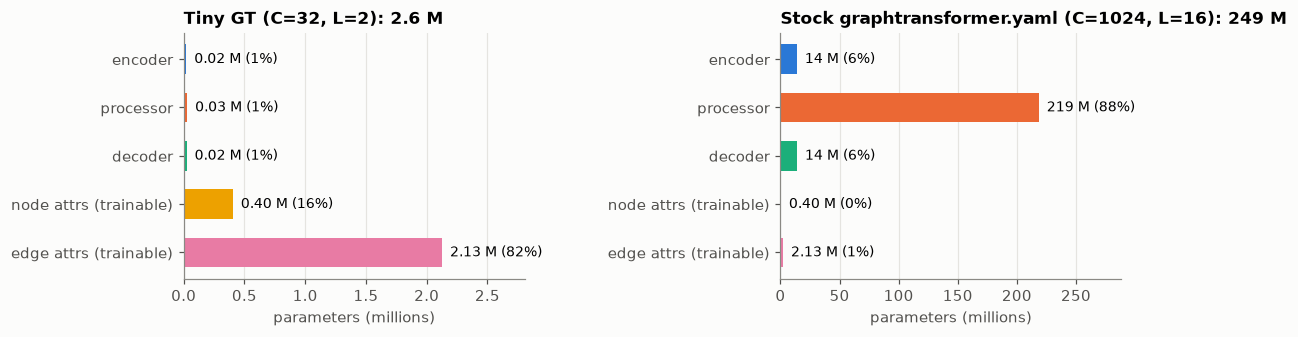

In [10]:
SEG_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # fixed order, one per component

def stacked_bar(ax, rows, title, unit=1e6, unit_label="M"):
    names = list(rows)
    for i, name in enumerate(names):
        left = 0
        for (comp, value), color in zip(rows[name].items(), SEG_COLORS):
            ax.barh(i, value / unit, left=left, color=color, height=0.55, edgecolor="#fcfcfb", linewidth=2,
                    label=comp if i == 0 else None)
            left += value / unit
        ax.text(left, i, f"  {left:.2f} {unit_label}", va="center", color="#0b0b0b", fontsize=9)
    ax.set_yticks(range(len(names)), names)
    ax.invert_yaxis()
    ax.set_xlabel(f"parameters ({unit_label})")
    ax.set_title(title, loc="left")
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.margins(x=0.18)

COMP_COLORS = dict(zip(COMPONENTS, SEG_COLORS))

def component_bars(ax, cnt, title):
    names = list(cnt)
    vals = np.array([cnt[k] for k in names]) / 1e6
    ax.barh(range(len(names)), vals, color=[COMP_COLORS[k] for k in names], height=0.62)
    tot = vals.sum()
    for i, v in enumerate(vals):
        ax.text(v, i, f"  {v:.2f} M ({v / tot:.0%})" if v < 10 else f"  {v:.0f} M ({v / tot:.0%})", va="center", fontsize=9)
    ax.set_yticks(range(len(names)), names)
    ax.invert_yaxis()
    ax.set_xlabel("parameters (millions)")
    ax.set_title(title, loc="left")
    ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.margins(x=0.32)

fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), gridspec_kw={"wspace": 0.75})
component_bars(axes[0], counts, f"Tiny GT (C=32, L=2): {sum(counts.values()) / 1e6:.1f} M")
component_bars(axes[1], counts_big, f"Stock graphtransformer.yaml (C=1024, L=16): {sum(counts_big.values()) / 1e6:.0f} M")
fig.savefig(OUTDIR / "03_param_breakdown.png", bbox_inches="tight")
plt.show()

At production size the processor holds almost 90 % of the weights, which is why it runs on the hidden mesh.
The trainable graph features are the same ~2.5 M in both models: they scale with the **graph**, not with the network width.

## 4 · Pre- and post-processing live *inside* the model (3 min)

### Normaliser: the dataset statistics, frozen into buffers
`InputNormalizer` turns each variable's statistics (notebook 01) into `x * mul + add`, using the method set per variable in `data/zarr.yaml`
(`mean-std` by default, `std` for `tp`, `max` for orography, `none` for the sin/cos forcings).
The two vectors are registered **buffers**, so they are saved in the `state_dict` together with the weights.

In [11]:
norm = model.pre_processors["data"].processors["normalizer"]
print([k for k in model.state_dict() if "pre_processors" in k])

x_norm = model.pre_processors["data"](x_in[:, :, None], in_place=False)  # add the ensemble dim
show = ["2t", "msl", "z_500", "q_850", "z", "cos_latitude"]
rows = []
pos = idx.model.input.name_to_index  # position *within the 99-variable model tensor* (see the gotcha below)
for v in show:
    i = pos[v]
    raw, nrm = x_in[..., i], x_norm[..., i]
    method = norm.methods.get(v, norm.default)
    rows.append({"variable": v, "method": method, "raw mean": f"{raw.mean():.4g}", "raw std": f"{raw.std():.4g}",
                 "normalised mean": f"{nrm.mean():.2f}", "normalised std": f"{nrm.std():.2f}"})
pd.DataFrame(rows).style.hide(axis="index")

['pre_processors.data.processors.normalizer._norm_mul', 'pre_processors.data.processors.normalizer._norm_add', 'pre_processors.data.processors.normalizer._input_idx', 'pre_processors.data.processors.normalizer._output_idx', 'pre_processors.data.processors.normalizer._model_output_idx']


variable,method,raw mean,raw std,normalised mean,normalised std
2t,mean-std,287.1,15.45,0.02,0.97
msl,mean-std,1.012e+05,1010,0.01,0.98
z_500,mean-std,5.553e+04,2703,0.01,1.01
q_850,mean-std,0.006118,0.00447,0.02,1.00
z,max,2277,6171,0.04,0.11
cos_latitude,none,0.7966,0.2275,0.80,0.23


> **Index gotcha.** `idx.data.*.name_to_index` gives positions in the *full dataset* (101 variables), `idx.model.input/output.name_to_index` gives positions in the tensors the model sees (99 in, 88 out). Use the model index for `x_in` and for predictions.

### Bounding: physical constraints as the last layer
`model.bounding` in the config adds layers that act on the model output, *after* the residual is added. The stock configs bound total precipitation with a `ReluBounding`.
Others in `anemoi.models.layers.bounding`: `HardtanhBounding` (e.g. fractions in [0, 1]), `FractionBounding` (e.g. `cp` as a fraction of `tp`), `NormalizedReluBounding` (a threshold other than 0).

Bounding is part of the model, not a post-hoc clip, for two reasons: the loss is computed on the *bounded* output, so training learns with the constraint in place,
and every checkpoint applies the constraint in inference without extra code.
Note that the ReLU acts in **normalised** space. That is why `tp` uses the `std` normaliser: it has no mean shift, so 0 mm stays at 0.

In [12]:
print(model.model.boundings)
tp = idx.model.output.name_to_index["tp"]
with torch.no_grad():
    raw_out = model.model({"data": model.pre_processors["data"](x_in[:, :, None], in_place=False)})["data"]
print(f"untrained tp output, normalised: min {raw_out[..., tp].min():.3f}, "
      f"fraction exactly 0: {(raw_out[..., tp] == 0).float().mean():.0%}")

ModuleDict(
  (data): ModuleList(
    (0): ReluBounding()
  )
)
untrained tp output, normalised: min 0.000, fraction exactly 0: 48%


The untrained model outputs `tp = 0` at about half of the grid points, but never a negative value. We can plot what the plumbing produces.
Because of the residual connection, an untrained model predicts "persistence + noise".

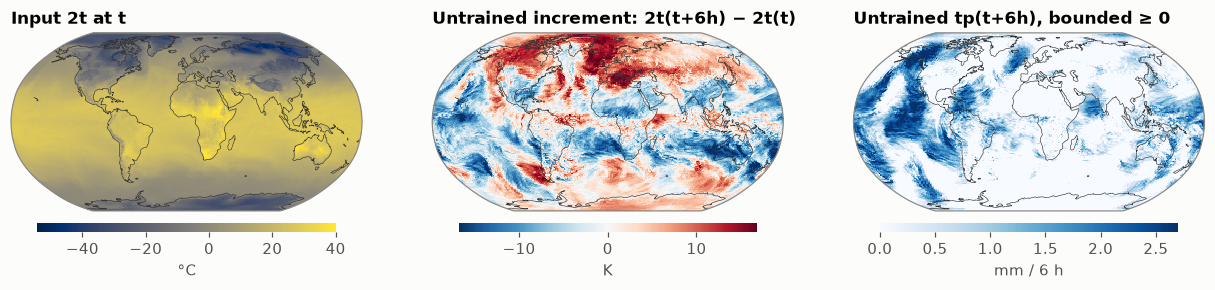

In [13]:
lat, lon = ds.latitudes, ds.longitudes
out_i = idx.model.output.name_to_index
in_i = idx.model.input.name_to_index    # positions in the 99-variable input tensor
t2_in = x_in[0, -1, :, in_i["2t"]].numpy()            # 2t at time t (last input step)
t2_out = y[0, 0, 0, :, out_i["2t"]].numpy()           # predicted 2t at t+6h
tp_out = y[0, 0, 0, :, out_i["tp"]].numpy() * 1000    # m -> mm

from scipy.spatial import cKDTree

def xyz(la, lo):
    la, lo = np.deg2rad(la), np.deg2rad(lo)
    return np.stack([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)], axis=-1)

# nearest-neighbour lookup from the O96 grid to a regular 0.5° grid, for clean maps
glon, glat = np.meshgrid(np.arange(-180, 180.01, 0.5), np.arange(-90, 90.01, 0.5))
_, NN = cKDTree(xyz(lat, lon)).query(xyz(glat.ravel(), glon.ravel()))
regrid = lambda v: np.asarray(v)[NN].reshape(glat.shape)

def panel(ax, values, title, cmap, label, vmin=None, vmax=None):
    sc = ax.pcolormesh(glon, glat, regrid(values), cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest",
                       transform=ccrs.PlateCarree(), rasterized=True)
    ax.coastlines(linewidth=0.4, color="#333333")
    ax.set_global()
    ax.set_title(title, loc="left")
    cb = plt.colorbar(sc, ax=ax, orientation="horizontal", pad=0.04, shrink=0.85, aspect=35)
    cb.set_label(label, color="#52514e")
    cb.outline.set_visible(False)

inc = t2_out - t2_in
lim = np.percentile(np.abs(inc), 99)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), subplot_kw={"projection": ccrs.Robinson()})
panel(axes[0], t2_in - 273.15, "Input 2t at t", "cividis", "°C")
panel(axes[1], inc, "Untrained increment: 2t(t+6h) − 2t(t)", "RdBu_r", "K", -lim, lim)
panel(axes[2], tp_out, "Untrained tp(t+6h), bounded ≥ 0", "Blues", "mm / 6 h", 0, np.percentile(tp_out, 99))
fig.savefig(OUTDIR / "03_untrained_maps.png", bbox_inches="tight")
plt.show()

### Imputer: NaNs in, NaNs out
Some fields have missing values (sea-surface temperature over land, radar outside its range).
A network cannot handle NaNs: one NaN spreads along every edge it touches.
An **imputer** fills them before the normaliser (e.g. with the variable mean, `InputImputer`, or a constant, `ConstantImputer`)
and puts the NaNs back in the output (`inverse_transform`).

To show this, we turn `skt` into a fake SST by setting it to NaN over land, and compare our model with a copy that has an imputer.
The imputer goes **first** in `data.datasets.data.processors`, because the processors run in config order.

In [14]:
lsm = x_in[0, -1, :, in_i["lsm"]]
x_nan = x_in.clone()
x_nan[..., lsm > 0.5, in_i["skt"]] = float("nan")
print(f"NaNs in input: {torch.isnan(x_nan).sum().item():,}  ({(lsm > 0.5).float().mean():.0%} of grid points, 'skt' only)")

cfg_imp = compose_config("graphtransformer")
imputer = OmegaConf.create({"imputer": {"_target_": "anemoi.models.preprocessing.imputer.InputImputer",
                                        "config": {"default": "none", "mean": ["skt"]}}})
cfg_imp.data.datasets.data.processors = OmegaConf.merge(imputer, cfg_imp.data.datasets.data.processors)
model_imp = build_model(cfg_imp).eval()
model_imp.model.load_state_dict(model.model.state_dict())  # same weights, only the pre-processing differs
print("pre-processors:", list(model_imp.pre_processors["data"].processors))

outs = {}
for name, mdl in [("without imputer", model), ("with imputer", model_imp)]:
    out = outs[name] = mdl.predict_step({"data": x_nan})["data"]
    nan_frac = torch.isnan(out).float().mean(dim=(0, 1, 2, 3))
    print(f"{name:16s}: output NaN fraction  skt {nan_frac[out_i['skt']]:.0%}   2t {nan_frac[out_i['2t']]:.0%}   all vars {torch.isnan(out).float().mean():.0%}")

NaNs in input: 23,130  (29% of grid points, 'skt' only)


pre-processors: ['imputer', 'normalizer']
without imputer : output NaN fraction  skt 75%   2t 75%   all vars 75%


with imputer    : output NaN fraction  skt 29%   2t 0%   all vars 0%


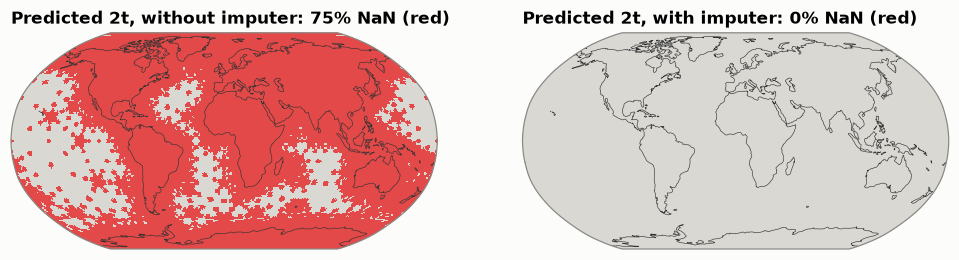

In [15]:
from matplotlib.colors import ListedColormap
nan_cmap = ListedColormap(["#d9d8d3", "#e34948"])  # valid, NaN
fig, axes = plt.subplots(1, 2, figsize=(11, 3), subplot_kw={"projection": ccrs.Robinson()})
for ax, (name, out) in zip(axes, outs.items()):
    isnan = torch.isnan(out[0, 0, 0, :, out_i["2t"]]).numpy()
    ax.pcolormesh(glon, glat, regrid(isnan), cmap=nan_cmap, vmin=0, vmax=1, shading="nearest",
                  transform=ccrs.PlateCarree(), rasterized=True)
    ax.coastlines(linewidth=0.4, color="#333333")
    ax.set_global()
    ax.set_title(f"Predicted 2t, {name}: {isnan.mean():.0%} NaN (red)", loc="left")
fig.savefig(OUTDIR / "03_imputer_nan_spread.png", bbox_inches="tight")
plt.show()

Without the imputer, the NaNs in one land-only field spread through the encoder, processor and decoder into **every variable** over most of the globe.
With it, the prediction is complete, and only `skt` is NaN, exactly where its input was NaN.
(Here `model` ran silently because its pre-processors had already been called once. On its **first** call, `Processors` checks for NaNs and raises an error, so in practice you notice early.)

### A checkpoint is self-contained
anemoi-training's inference checkpoint is `torch.save(model)` of this interface (`training/utils/checkpoint.py`).
Because normaliser, imputer, bounding, data indices and graph are all inside, the reloaded file needs **no dataset, no statistics file and no config** to produce a forecast in physical units:

In [16]:
ckpt = OUTDIR / "03_tiny_graphtransformer.pt"
torch.save(model, ckpt)
print(f"{ckpt.name}: {ckpt.stat().st_size / 1e6:.1f} MB")

reloaded = torch.load(ckpt, weights_only=False)  # full pickle: only load checkpoints you trust
y2 = reloaded.predict_step({"data": x_in})["data"]
print("same prediction after reload:", torch.allclose(y, y2))

03_tiny_graphtransformer.pt: 24.7 MB


same prediction after reload: True


## 5 · Swap the processor (2 min)

The processor is one Hydra target. Swapping it is a matter of choosing `model=gnn`, `model=graphtransformer` or `model=transformer`.
The mappers change with it in the stock files: GNN mappers for `gnn.yaml`, GraphTransformer mappers for the other two.

The `TransformerProcessor` ignores processor edges: it attends within a sliding window of `window_size` neighbouring hidden nodes.
Its model refuses a graph that *has* `hidden→hidden` edges, so we drop them (in training you would use `graph=encoder_decoder_only`).

In [17]:
%%time
graph_no_proc = copy.copy(graph)
del graph_no_proc["hidden", "to", "hidden"]

models = {
    "graphtransformer": model,
    "gnn": build_model(compose_config("gnn")).eval(),
    "transformer": build_model(compose_config("transformer"), graph=graph_no_proc).eval(),
}

x_proc = {"data": model.pre_processors["data"](x_in[:, :, None], in_place=False)}  # the model takes a dict: one tensor per dataset
timings = {}
with torch.no_grad():
    for name, mdl in models.items():
        mdl.model(x_proc)  # warm-up (first call is much slower)
        runs = []
        for _ in range(5):
            t0 = time.perf_counter()
            mdl.model(x_proc)
            runs.append(time.perf_counter() - t0)
        timings[name] = np.array(runs)

summary = pd.DataFrame({
    name: {**count_params(mdl), "total": sum(count_params(mdl).values()),
           "forward ms (median)": round(1000 * np.median(timings[name]))}
    for name, mdl in models.items()
}).T
summary

CPU times: user 17.8 s, sys: 5.36 s, total: 23.2 s
Wall time: 7.82 s


,encoder,processor,decoder,node attrs (trainable),edge attrs (trainable),total,forward ms (median)
graphtransformer,21376,28288,23928,404496,2126240,2604328,112
gnn,23616,21632,17112,404496,2126240,2593096,102
transformer,21376,25216,23928,404496,1471520,1946536,546


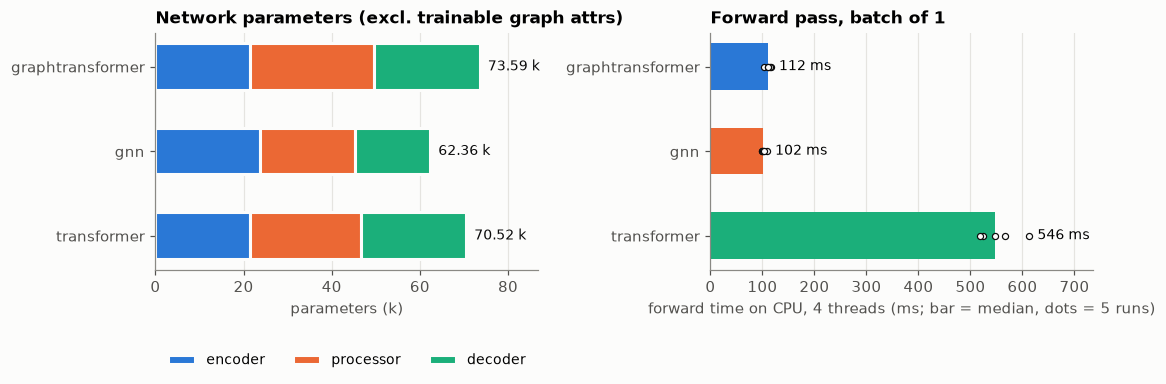

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), gridspec_kw={"wspace": 0.45})
names = list(models)
net = {n: {k: v for k, v in count_params(models[n]).items() if k in ("encoder", "processor", "decoder")} for n in names}
stacked_bar(axes[0], net, "Network parameters (excl. trainable graph attrs)", unit=1e3, unit_label="k")
axes[0].legend(ncol=3, bbox_to_anchor=(0, -0.3), loc="upper left", frameon=False, fontsize=9)

ax = axes[1]
for i, n in enumerate(names):
    ms = 1000 * timings[n]
    ax.barh(i, np.median(ms), color=COLORS[n], height=0.55)
    ax.plot(ms, np.full_like(ms, i), "o", ms=4, mfc="#fcfcfb", mec="#0b0b0b", mew=0.8)
    ax.text(ms.max(), i, f"  {np.median(ms):.0f} ms", va="center", fontsize=9)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel(f"forward time on CPU, {N_THREADS} threads (ms; bar = median, dots = 5 runs)")
ax.set_title("Forward pass, batch of 1", loc="left")
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.margins(x=0.2)
fig.savefig(OUTDIR / "03_processor_comparison.png", bbox_inches="tight")
plt.show()

Take these CPU timings as relative only: on a GPU the GraphTransformer uses a fused Triton kernel and the Transformer uses flash attention.
At this tiny width every variant has a similar number of weights. What differs is the operation: a GNN applies the same MLP update to every edge,
a GraphTransformer adds attention over the graph edges, and the sliding-window Transformer does dense attention inside its window, so its cost grows with `window_size`.

**Recap**

* `AnemoiModelInterface` = pre-processors + `AnemoiModelEncProcDec` + post-processors, built from the `model:` and `data:` config groups, the data indices, the dataset statistics and the graph.
* Shapes: `(B, T, E, G, V)` → `(B·E·G, T·V + attrs)` → encoder → `(B·H, C)` → processor (L layers, hidden mesh) → decoder → `(B, 1, E, G, V_out)` + residual + bounding.
* Normaliser, imputer and bounding are layers of the model, so a checkpoint is self-contained.
* The processor is one config key. It holds most of the compute and the weights at production size.

## 6 · Try it

**Exercise 1: how does the processor scale?** Build GraphTransformer models with `num_channels` 32 → 64 and `num_layers` 2 → 4.
Predict first: how should the processor's parameter count change in each case? Then check with `count_params`.

<details><summary>Solution (click to expand)</summary>

```python
for C, L in [(32, 2), (64, 2), (32, 4)]:
    p = count_params(build_model(compose_config("graphtransformer", num_channels=C, num_layers=L)))["processor"]
    print(f"C={C:3d} L={L}: processor {p:,}")
```
Doubling `num_layers` doubles the processor (each layer has the same size).
Doubling `num_channels` roughly **quadruples** it, because the attention projections and the MLP are C×C matrices.
That is how 32 channels and 2 layers become ~220 M processor parameters at 1024 channels and 16 layers.
</details>

In [19]:
# Exercise 1: your code here

**Exercise 2: a bounding that does not do what you think.** Add a `ReluBounding` for specific humidity `q_850` to the model config and build the model.
Does it guarantee `q_850 ≥ 0` in **physical** units? Check `data.datasets.data.processors.normalizer` for the method `q_850` uses.
Which bounding class fixes it?

<details><summary>Solution (click to expand)</summary>

`q_850` uses the default `mean-std` normaliser, so the ReLU clips at the **mean** (normalised 0), not at 0 kg/kg.
The prediction would never go below the climatological mean, which is wrong in a different way.
Use `NormalizedReluBounding`: it converts the physical threshold into normalised space.

Bounding is a list in the config (`model.bounding.datasets.data`), so append to it in Python:

```python
cfg_b = compose_config("graphtransformer")
cfg_b.model.bounding.datasets.data.append(OmegaConf.create({
    "_target_": "anemoi.models.layers.bounding.NormalizedReluBounding",
    "variables": ["q_850"], "min_val": [0.0], "normalizer": ["mean-std"]}))
mb = build_model(cfg_b).eval()
q = mb.predict_step({"data": x_in})["data"][..., idx.model.output.name_to_index["q_850"]]
print(mb.model.boundings, "min q_850 =", q.min().item())   # >= 0 in kg/kg
```
</details>

In [20]:
# Exercise 2: your code here